Implements raster and vector analysis using the TI-City model results and its spatial inputs.

### Authorship
@author: Alexandre Pereira Santos <br>
alexandre.santos(at)lmu.de<br>
- usespandas, geopandas, rasterio, rasterstats
- may include content from LLMs

### Features
1. Load ASCII files with ti-city NetLogo output
2. Assemble the ASCIIs as n-dimensional numpy vector, with n=number of runs
3. Load pre-calculated exposure metrics (TBD: segment exposure across RCP scenarios)
4. Calculate statistics for all runs (mean exposure, exposure per SEP, and vulnerability index [vuln = exposure degree * SEP class]
5. Plot stats as 
   1. Exposure vs. vulnerability map (t=2050) for each scenario
   2. Vulnerability index per scenario (line plot?), time on the x-axis

# Imports

In [1]:
import pandas as pd
import geopandas as gpd

import os
from pathlib import Path
#import fnmatch
#import shutil

import numpy as np
import random 
import matplotlib.pyplot as plt
#import matplotlib.colors as mcolors
#import matplotlib.patches as mpatches
import natsort

#from shapely.geometry.polygon import Polygon
#from shapely.geometry import MultiLineString, LineString
#import json

import rasterio
from rasterio.mask import mask
from rasterio.plot import show, show_hist, plotting_extent
from rasterio.warp import reproject, calculate_default_transform, Resampling
from rasterio.features import dataset_features
import rasterstats
#from libpysal.weights import lat2W, Rook
#from esda.moran import Moran

from ti_city_00_helper_functions import *
from ti_city_08_fuzzy_fom_validation_module import *

Cannot find header.dxf (GDAL_DATA is not defined)


# init

In [2]:
#%%time

case_city = 'JAK' #MUM MAN JAK
drop_path = r'C:\\Sciebo\\05_GIS\\' # adjust this to match the path on your computer, e.g. 'D:\\Dropbox\\x\\PostDoc\\GIS' or 'C:\\Users\\x\\Dropbox\\x\\PostDoc\\GIS'
external_data_path = Path(r'C:\\Sciebo\\00_data') # adjust this to match the path on your computer, e.g. 'D:\\Dropbox\\x\\PostDoc\\00_data' or 'C:\\Users\\x\\Dropbox\\x\\PostDoc\\00_data'
## ascii150_arcgis_path = Path(r"D:\\Dropbox\\x\\PostDoc\ASCII_150m") deprecated, ignore

#input a vector and a raster file for each city
AOI_path = Path(f'{drop_path}\\{case_city}\\processed\\')
AOI_file = f'{case_city}_LIM_AOI_reference_150m_A.shp' # APS: updated AOI 01.08.2024

AOI_gdf = gpd.read_file(AOI_path / AOI_file) #.to_crs(epsg=4326)
AOI_gdf_4326 = AOI_gdf.to_crs(epsg=4326) 

ref_raster_path = Path(f'../data/processed/{case_city}_LIM_reference_AOI_150m.tif')
ref_raster_150_path = Path(f'../data/processed/{case_city}_LIM_reference_AOI_150m.tif')

raw_path = Path(f'\\{case_city}\\raw\\')
interim_path = Path(drop_path + f'{case_city}\\interim\\')
processed_path = Path(drop_path + f'{case_city}\\processed\\')
external_path = Path(drop_path + f'{case_city}\\external\\')
model_inputs_30m_path = Path(drop_path + f'{case_city}\\model_inputs\\TIFF_30m\\')
model_inputs_150m_path = Path(drop_path + f'{case_city}\\model_inputs\\TIFF_150m\\')
model_inputs_SLEUTH_150m_path = Path(drop_path + f'{case_city}\\model_inputs\\TIFF_SLEUTH_150m')
model_outputs_path = Path(drop_path + f'{case_city}\\model_outputs\\') 
ascii150_path = Path(drop_path + f'\\{case_city}\\model_inputs\\ASCII_150m')
ascii150_SLEUTH_path = Path(drop_path + f'\\{case_city}\\model_inputs\\ASCII_SLEUTH_150m')
ti_city_ascii_path = Path(f'../model/{case_city}/data/in/')
ti_city_out_path = Path(f'../model/{case_city}/data/out/')
ref_raster_sleuth_path = model_inputs_SLEUTH_150m_path / (case_city + '_URB_SLEUTH_input_2022.tif' )

if case_city == 'MUM':
    gadm_var = 'NAME_3'
    calibration_years = [2015,2025]
    simulation_years = [2025, 2050]

if case_city == 'MAN':    
    gadm_var = 'NAME_2'
    calibration_years = [2015,2025]
    simulation_years = [2025, 2050]

if case_city == 'JAK':
    gadm_var = 'NAME_3'
    calibration_years = [2000,2025]
    simulation_years = [2025, 2050]

# read the reference raster
with rasterio.open(ref_raster_path,'r') as src: # APS 20.08.2025 using the 150 m raster
    ref_raster = src
    ref_meta = src.meta
    ref_height, ref_width, ref_area = get_transform(ref_raster)

# suppress deprecation warnings
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

# first, let's inform the scenario folders
# APS: 15.05.2026 I updated the folder and file naming convention to allow for individual results per tick
# example: "D:\GIT\ti-city-model\model\JAK\data\out\R037\expansion_income_t0.asc"


# let's build dictionaries to support the loading functions
agent_class_dict = {'na':0,'low': 1, 'mid': 2, 'high': 3, 'deprived': 4, 'urban_2022': 5}
#APS 11.08.2026 previously: ['std', 'ssp1', 'ssp2', 'ssp3']
#APS 22.10.2026 previously: ['S1', 'S2', 'S3', 'S4'] 
ascii_files = [] # initialize the list of ASCII files

def load_ascii_files(scenarios, scenario_path, load_mode = 'final', results_folder=model_outputs_path, file_name_template = 'expansion_income_t', export_tiff=False, export_path=model_outputs_path, silent=False):
    results_dict = {}
    for scenario in scenarios:
        path = results_folder / scenario_path[scenario]
        if not silent:
            print(f'Processing content from: {scenario} at {path}')
        # example: "D:\GIT\ti-city-model\model\JAK\data\out\R037\expansion_income_t0.asc"
        # list and count the files in this folder
        ascii_files = [f for f in os.listdir(path) if f.endswith('.asc')]
        ascii_files = natsort.natsorted(ascii_files)  # Natural sorting
        #print(ascii_files)
        # build a dict containing the ASCII files with the structure scenario > n-runs
        results_dict[scenario] = {}#{'list': ascii_files}
        if load_mode == 'final':
            # load only the last tick (the final result) for each scenario
            print(f'Loading only the final tick for scenario: {scenario}')
            if ascii_files:
                last_file = ascii_files[-1]
                
                key = Path(last_file).stem
                if key.startswith(file_name_template):
                    key = key[len(file_name_template):]
                    if not silent:
                        print(f'Extracted key: {key} from file: {last_file}')
                else:
                    key = key.split('t')[-1]
                    if not silent:
                        print(f'Extracted key-1: {key} from file: {last_file}')
                url = path / last_file
                with rasterio.open(url, 'r') as src:
                    array = src.read(1)
                    array_meta = src.meta
                results_dict[scenario][key] = array
        elif load_mode == 'all':
            # load all ticks for each scenario
            print(f'Loading all ticks for scenario: {scenario}')
            for file in ascii_files:
                key = Path(file).stem
                if key.startswith(file_name_template):
                    key = key[len(file_name_template):]
                    if not silent:
                        print(f'Extracted key: {key} from file: {file}')
                else:
                    key = key.split('t')[-1]
                    if not silent:
                        print(f'Extracted key-1: {key} from file: {file}')

                url = path / file
                with rasterio.open(url, 'r') as src:
                    array = src.read(1)
                    array_meta = src.meta
                results_dict[scenario][key] = array
    if export_tiff:
        for scenario, runs in results_dict.items():
            dir_path = export_path / scenario_path_dict[scenario]
            dir_path.mkdir(parents=True, exist_ok=True)
            for run_key, raster in runs.items():
                try:
                    tick = int(run_key)
                    tick_str = f"{tick:03d}"
                except Exception:
                    tick_str = run_key
                file_name = f"{case_city}_TI-City_results_{scenario}_t{tick_str}.tif"
                url = dir_path / file_name
                print(url)
                export_raster(
                    raster=raster.astype('int16'),
                    url=url,
                    data_type=rasterio.int16,
                    ref_raster_path=ref_raster_150_path
                )
    return results_dict

def compile_scenarios_table(
    results_dict,
    baseline_dict,
    exposure_raster,
    start_year = simulation_years[0],
    cell_area=0.150 * 0.150,
    export_results_table=True,
    export_path=model_outputs_path
):
    agent_class_dict = {
        'na': 0, 'deprived': 1, 'low': 2, 'mid': 3,
        'high': 4, 'urban_first_year': 5
    }
    descriptive_dict = {}

    for scenario, series in results_dict.items():
        sorted_keys = natsort.natsorted(series.keys())
        descriptive_dict[scenario] = {}

        for key in sorted_keys:
            raster = series[key]
            year = start_year + int(key)

            stats_dict = {}
            stats_dict['New urban cells'] = np.count_nonzero(
                (raster > 0) & (raster <= 4)
            )
            stats_dict['Total Urban Area'] = np.round(
                np.sum(raster > 0) * cell_area, 2
            )
            stats_dict['Urban Area Exposed to Flooding'] = np.round(
                np.sum((raster > 0) & (exposure_raster > 0)) * cell_area, 2
            )
            stats_dict['Total New Urban Area'] = np.round(
                stats_dict['Total Urban Area']
                - np.sum(raster == agent_class_dict['urban_first_year']) * cell_area,
                2
            )
            stats_dict['New Urban Area Exposed to Flooding'] = np.round(
                stats_dict['Urban Area Exposed to Flooding']
                - np.sum(
                    (raster == agent_class_dict['urban_first_year'])
                    & (exposure_raster > 0)
                ) * cell_area,
                2
            )

            # Compare this result with each baseline raster.
            for baseline_name, baseline_series in baseline_dict.items():
                if key in baseline_series:
                    baseline_raster = baseline_series[key]
                elif len(baseline_series) == 1:
                    baseline_raster = next(iter(baseline_series.values()))
                else:
                    raise KeyError(
                        f"No baseline raster for tick {key!r} in "
                        f"{baseline_name!r}."
                    )

                if baseline_raster.shape != raster.shape:
                    raise ValueError(
                        f"Raster shape mismatch for baseline {baseline_name!r}: "
                        f"{baseline_raster.shape} != {raster.shape}"
                    )

                new_cells = (baseline_raster > 0) & (baseline_raster <= 4)
                stats_dict[f'new_cells_{baseline_name}'] = int(
                    np.count_nonzero(new_cells)
                )
                stats_dict[f'new_area_{baseline_name}'] = np.round(
                    np.count_nonzero(new_cells) * cell_area, 2
                )

            for class_name, class_id in agent_class_dict.items():
                if class_name == 'na':
                    continue

                stats_dict[f'Urban Area ({class_name})'] = np.round(
                    np.sum(raster == class_id) * cell_area, 2
                )
                stats_dict[f'Urban Area Exposed ({class_name})'] = np.round(
                    np.sum((raster == class_id) & (exposure_raster > 0))
                    * cell_area,
                    2
                )

            descriptive_dict[scenario][year] = stats_dict

    rows = []
    for scenario, years in descriptive_dict.items():
        for year, stats in years.items():
            row = {"Scenario": scenario, "Year": year}
            row.update(stats)
            rows.append(row)

    results_table = pd.DataFrame(rows)
    results_table = results_table.sort_values(
        ["Scenario", "Year"]
    ).reset_index(drop=True)

    results_table["Total Urban Area"] = results_table[
        [
            "Urban Area (deprived)",
            "Urban Area (low)",
            "Urban Area (mid)",
            "Urban Area (high)"
        ]
    ].sum(axis=1)

    for class_name in ("deprived", "low", "mid", "high"):
        results_table[f"Urban Area ({class_name}) Percentage"] = (
            results_table[f"Urban Area ({class_name})"]
            / results_table["Total Urban Area"] * 100
        ).round(2)

    exposure_columns = [
        f"Urban Area Exposed ({class_name})"
        for class_name in ("deprived", "low", "mid", "high")
    ]
    results_table["Urban Area Exposed (total)"] = results_table[
        exposure_columns
    ].sum(axis=1)

    for class_name in ("deprived", "low", "mid", "high"):
        results_table[f"Urban Area Exposed ({class_name}) Percentage"] = (
            results_table[f"Urban Area Exposed ({class_name})"]
            / results_table["Urban Area Exposed (total)"] * 100
        ).round(2)

    if export_results_table:
        output_file = export_path / (
            f"{case_city}_urban_exposed_areas_analysis_"
            f"{scenario_path_dict[scenario_list[0]].rstrip('/')}_"
            f"{scenario_path_dict[scenario_list[-1]].rstrip('/')}.xlsx"
        )
        results_table.to_excel(output_file, index_label="ID")
        print(f"Results table exported to {output_file}")

    return results_table

c:\Users\santos\.conda\envs\x\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


# 1. import the regions for analysis

Urban early raster: (680, 772)
Urban late raster: (680, 772)


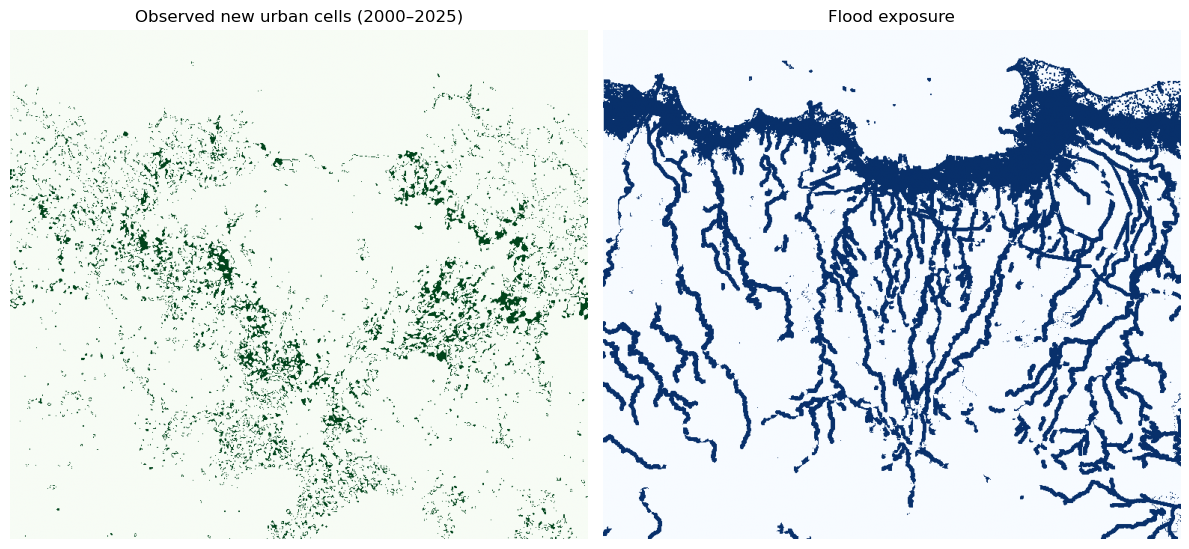

In [3]:
exposure_areas_path = None
if case_city == 'MAN':
    file_name = case_city + '_HYD_25_year_flooding_surgeSSA1_reclass_150m.tif'
    exposure_areas_path = model_inputs_150m_path / file_name
elif case_city == 'JAK':
    file_name = case_city + '_HYD_flood_hazard_150m.tif'
    exposure_areas_path = interim_path / file_name
elif case_city == 'MUM':
    file_name = case_city + '_HYD_flood_hazard_150m.tif'
    exposure_areas_path = interim_path / file_name

with rasterio.open(exposure_areas_path,'r') as src:
    exposure_raster = src.read(1)
    exposure_raster_meta = src.meta
    # we have to adjust the area of the exposure raster to that of the results
#print('Exposure raster:', exposure_raster.shape)
#plot_unique_value_raster(exposure_raster)
#plot_continuous_raster(exposure_raster)
#plot_unique_value_raster(exposure_raster, title='Areas exposed to flooding (25 years return) and storm surge')

# load urbanisation reference rasters for the calibration years
# early = first year of calibration period calibration_years[0]
# late = last year of calibration period calibration_years[1]

urban_early_file = case_city + f'_URB_urbanisation_{calibration_years[0]}_GHSL_150m.tif'
urban_early_path = model_inputs_150m_path / urban_early_file
with rasterio.open(urban_early_path,'r') as src:
    urban_early_raster = src.read(1)
    urban_early_raster_meta = src.meta
print('Urban early raster:', urban_early_raster.shape)

urban_late_file = case_city + f'_URB_urbanisation_{calibration_years[1]}_GHSL_150m.tif'
urban_late_path = model_inputs_150m_path / urban_late_file
with rasterio.open(urban_late_path,'r') as src:
    urban_late_raster = src.read(1)
    urban_late_raster_meta = src.meta
print('Urban late raster:', urban_late_raster.shape)

# Extract observed new-urban cells (2000-2025) on the 150 m AOI grid
new_cells_observed = observed_new_from_rasters(urban_late_raster, urban_early_raster).astype(np.uint8)

#plot new_cells_observed
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(new_cells_observed, cmap='Greens', vmin=0, vmax=1)
axes[0].set_title(
    f'Observed new urban cells ({calibration_years[0]}–{calibration_years[1]})'
)
axes[0].axis('off')

axes[1].imshow(exposure_raster > 0, cmap='Blues', vmin=0, vmax=1)
axes[1].set_title('Flood exposure')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## .1 compile descriptive stats 
on the population for each SSP considering socioconomic profile and exposure

In [4]:
# this import loads the calibration scenario (S0a) 
# and three baseline scenarios for comparison: random (S0b), 
# edge-growth (S0c), and road-based growth (S0d)
scenario_name_dict = {
    'S0a': 'Calibration scenario',
    'S_random': 'Random scenario',
    'S_edge': 'Edge growth scenario',
    'S_roadbound': 'Road growth scenario'
}

scenario_list = ['S0'] #, 'S0b', 'S0c', 'S0d']
scenario_path_dict = {'S0': 'R094/'} # consider the output_folder

baseline_list = ['S_random', 'S_edge', 'S_roadbound']
baseline_path_dict = {
    'S_random': 'R095/',
    'S_edge': 'R096/',
    'S_roadbound': 'R097/'
}

results_dict = load_ascii_files(
    scenarios = scenario_list,
    scenario_path = scenario_path_dict,
    results_folder=ti_city_out_path,
    file_name_template='expansion_income_t',
    export_tiff=False,
    export_path=model_outputs_path,
    silent=False)
baseline_dict = load_ascii_files(
    scenarios = baseline_list,
    scenario_path = baseline_path_dict,
    results_folder=ti_city_out_path,
    file_name_template='expansion_income_t',
    export_tiff=False,
    export_path=model_outputs_path,
    silent=False)
baseline_dict['Observed'] = {'025':new_cells_observed}
results_table = compile_scenarios_table(
    results_dict = results_dict,
    baseline_dict = baseline_dict,
    exposure_raster = exposure_raster,
    start_year = calibration_years[0],
    cell_area=0.150*0.150, 
    export_results_table=True, 
    export_path=model_outputs_path)

Processing content from: S0 at ..\model\JAK\data\out\R094
Loading only the final tick for scenario: S0
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: S_random at ..\model\JAK\data\out\R095
Loading only the final tick for scenario: S_random
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: S_edge at ..\model\JAK\data\out\R096
Loading only the final tick for scenario: S_edge
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: S_roadbound at ..\model\JAK\data\out\R097
Loading only the final tick for scenario: S_roadbound
Extracted key: 025 from file: expansion_income_t025.asc
Results table exported to C:\Sciebo\05_GIS\JAK\model_outputs\JAK_urban_exposed_areas_analysis_R094_R094.xlsx


In [29]:
print(baseline_dict.keys())

dict_keys(['S_random', 'S_edge', 'S_roadbound', 'Observed'])


## .2 Compare model results with the urbanisation calibration data

### comparing two scenarios

In [7]:
# compare the total urban area in the calibration results in [scenario_list[3]]['025'] with the urban_late cell count
urban_area_early = np.count_nonzero(urban_early_raster == 1)
urban_area_late = np.count_nonzero(urban_late_raster == 1) - urban_area_early
calibration_list = ['S0a', 'S0b', 'S0c', 'S0d']
# 'S0a', S0 calibration aiming at reproducing observed growth, HH 28866
# 'S0b', S1 random scenario weights (for all agents)
# 'S0c', S2 edge growth only - weight 10 for BU (built up) layers
# 'S0d', S3 pure road growth - weight 10 for road layers

urban_area_calib = np.count_nonzero((results_dict[scenario_list[0]]['025'] > 0) & (results_dict[scenario_list[0]]['025'] < 5))
#urban_area_calib = (np.nansum(results_dict[scenario_list[3]]['025']) ) - urban_area_early  # assuming each cell is 150m x 150m
#urban_area_late = (np.nansum(urban_late_raster) ) - urban_area_early  # assuming each cell is 150m x 150m
difference_area = urban_area_calib - urban_area_late
proportion_difference = (difference_area / urban_area_late) * 100 if urban_area_late != 0 else 0

# Compare urban areas; format values with thousand separators
print(f'Urban cells in {calibration_years[0]}: {urban_area_early:,}')
print(f"New urban area {calibration_years[1]} input reference: {urban_area_late:,.0f} cells")
print(f"New urban area in calibration ({scenario_list[0]}, 2025): {urban_area_calib:,.0f} cells")
print(f"Difference in new urban area: {difference_area:,.0f} cells, or {proportion_difference:.2f}% of the urban cells in {calibration_years[1]}")


Urban cells in 2000: 126,252
New urban area 2025 input reference: 28,866 cells
New urban area in calibration (S0, 2025): 28,889 cells
Difference in new urban area: 23 cells, or 0.08% of the urban cells in 2025


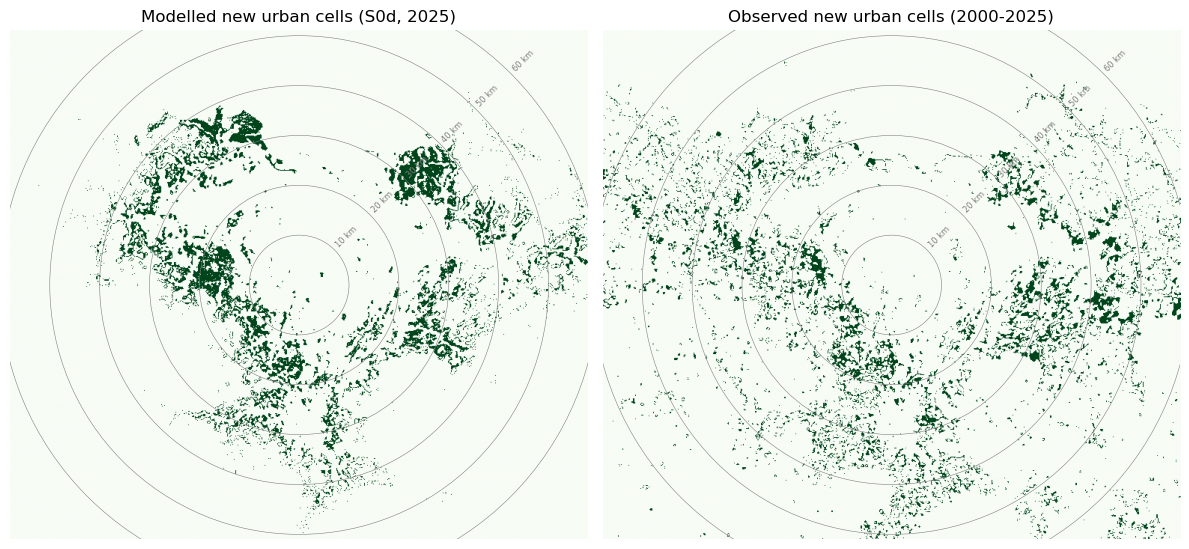

In [89]:
# plot the new urban cells raster
model_output_cells_raster = (results_dict[scenario_list[3]]['025'] > 0) & (results_dict[scenario_list[3]]['025'] < 5)
new_urban_cells_raster = np.where(model_output_cells_raster, 1, 0)  # Convert boolean to integer (1 for new urban cells, 0 otherwise)
new_late_urban_cells_raster = (urban_late_raster == 1) & (urban_early_raster == 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)

transform = urban_late_raster_meta["transform"]
pixel_width = abs(transform.a)
pixel_height = abs(transform.e)

height, width = model_output_cells_raster.shape
center_x, center_y = width / 2, height / 2

for ax, raster, title in zip(
    axes,
    [model_output_cells_raster, new_late_urban_cells_raster],
    [
        f"Modelled new urban cells ({scenario_list[3]}, {calibration_years[1]})",
        f"Observed new urban cells ({calibration_years[0]}-{calibration_years[1]})",
    ],
):
    ax.imshow(raster, cmap="Greens", vmin=0, vmax=1)

    for distance_km in [10, 20, 30, 40, 50, 60]:
        radius_m = distance_km * 1000
        radius_x = radius_m / pixel_width
        radius_y = radius_m / pixel_height

        ring = plt.matplotlib.patches.Ellipse(
            (center_x, center_y),
            width=2 * radius_x,
            height=2 * radius_y,
            fill=False,
            edgecolor="grey",
            linewidth=0.4,
        )
        ax.add_patch(ring)
        label_x = (center_x + radius_x / np.sqrt(2)) 
        label_y = (center_y - radius_y / np.sqrt(2)) 
        ax.text(
            label_x,
            label_y,
            f"{distance_km} km",
            color="grey",
            fontsize=6,
            ha="left",
            va="bottom",
            rotation=45,
        )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [62]:
# let's export each of the new urban cells rasters to a PNG file for further analysis
suffix = f"{scenario_path_dict[scenario_list[0]].rstrip('/')}_{scenario_path_dict[scenario_list[3]].rstrip('/')}_{calibration_years[0]}_{calibration_years[1]}"
for i, (raster, inner_suffix) in enumerate(zip([model_output_cells_raster, new_late_urban_cells_raster], [f'{suffix}_simulation', f'{suffix}_observation'])):
    png_path = model_outputs_path / f"{case_city}_new_urban_cells_{inner_suffix}.png"
    plt.imsave(png_path, raster, cmap="Greens", vmin=0, vmax=1)
    print(f"New urban cells raster in {suffix} exported to {png_path}")

New urban cells raster in R090_R093_2000_2025 exported to C:\Sciebo\05_GIS\JAK\model_outputs\JAK_new_urban_cells_R090_R093_2000_2025_simulation.png
New urban cells raster in R090_R093_2000_2025 exported to C:\Sciebo\05_GIS\JAK\model_outputs\JAK_new_urban_cells_R090_R093_2000_2025_observation.png


In [63]:
# export the new urban cells raster to a TIFF file
model_output_cells_tiff = model_outputs_path / f"{case_city}_new_urban_cells_{suffix}.tif"
export_raster(
    raster=new_urban_cells_raster.astype('int16'),
    url=model_output_cells_tiff,
    data_type=rasterio.int16,
    ref_raster_path=ref_raster_150_path
)
print(f"New urban cells raster exported to {model_output_cells_tiff}")

New urban cells raster exported to C:\Sciebo\05_GIS\JAK\model_outputs\JAK_new_urban_cells_R090_R093_2000_2025.tif


In [64]:
# export the raster again as CSV for further analysis
new_urban_cells_csv_path = model_outputs_path / f"{case_city}_new_urban_cells_{suffix}.csv"
# Convert the raster to a DataFrame
new_urban_cells_df = pd.DataFrame(new_urban_cells_raster.flatten())
new_urban_cells_df.to_csv(new_urban_cells_csv_path, index=False)
print(f"New urban cells raster exported to {new_urban_cells_csv_path}")

New urban cells raster exported to C:\Sciebo\05_GIS\JAK\model_outputs\JAK_new_urban_cells_R090_R093_2000_2025.csv


In [65]:
# export the new_late_urban_cells_raster as a csv as well
urban_late_new_cells_csv_path = model_outputs_path / f"{case_city}_urban_late_cells_{suffix}.csv"
urban_late_new_cells_df = pd.DataFrame(new_late_urban_cells_raster.flatten())
urban_late_new_cells_df.to_csv(urban_late_new_cells_csv_path, index=False)
print(f"New late urban cells raster exported to {urban_late_new_cells_csv_path}")

New late urban cells raster exported to C:\Sciebo\05_GIS\JAK\model_outputs\JAK_urban_late_cells_R090_R093_2000_2025.csv


### comparing four scenarios: calibration, random, edge-growth, and road

In [18]:
scenario_list = ['S0a', 'S0b', 'S0c', 'S0d']
scenario_path_dict = {'S0a': 'R094/', 'S0b': 'R095/', 'S0c': 'R096/', 'S0d': 'R097/'} # consider the output_folder
results_dict_ascii = {}
results_dict = load_ascii_files(
    scenarios = scenario_list,
    scenario_path = scenario_path_dict,
    results_folder=ti_city_out_path,
    file_name_template='expansion_income_t',
    export_tiff=False,
    export_path=model_outputs_path,
    silent=False)
results_table = compile_scenarios_table(
    results_dict,
    baseline_dict,
    exposure_raster, 
    start_year = simulation_years[0],
    cell_area=0.150*0.150, 
    export_results_table=True, 
    export_path=model_outputs_path)

# compare the total urban area in the calibration results in [scenario_list[3]]['025'] with the urban_late cell count
urban_area_early = np.count_nonzero(urban_early_raster == 1)
urban_area_late = np.count_nonzero(urban_late_raster == 1) - urban_area_early

# 'S0a', S0 calibration aiming at reproducing observed growth, HH 28866
# 'S0b', S1 random scenario weights (for all agents)
# 'S0c', S2 edge growth only - weight 10 for BU (built up) layers
# 'S0d', S3 pure road growth - weight 10 for road layers

urban_area_calib = np.count_nonzero((results_dict[scenario_list[0]]['025'] > 0) & (results_dict[scenario_list[0]]['025'] < 5))
urban_area_random = np.count_nonzero((results_dict[scenario_list[1]]['025'] > 0) & (results_dict[scenario_list[1]]['025'] < 5))
urban_area_edge = np.count_nonzero((results_dict[scenario_list[2]]['025'] > 0) & (results_dict[scenario_list[2]]['025'] < 5))
urban_area_road = np.count_nonzero((results_dict[scenario_list[3]]['025'] > 0) & (results_dict[scenario_list[3]]['025'] < 5))

difference_area_calib = urban_area_calib - urban_area_late
difference_area_random = urban_area_random - urban_area_late
difference_area_edge = urban_area_edge - urban_area_late
difference_area_road = urban_area_road - urban_area_late

proportion_difference_calib = (difference_area_calib / urban_area_late) * 100 if urban_area_late != 0 else 0
proportion_difference_random = (difference_area_random / urban_area_late) * 100 if urban_area_late != 0 else 0
proportion_difference_edge = (difference_area_edge / urban_area_late) * 100 if urban_area_late != 0 else 0
proportion_difference_road = (difference_area_road / urban_area_late) * 100 if urban_area_late != 0 else 0

# Compare urban areas; format values with thousand separators
print(f'Urban cells in {calibration_years[0]}: {urban_area_early:,}')
print(f"New urban area {calibration_years[1]} input reference: {urban_area_late:,.0f} cells")
print(f"New urban area in calibration ({scenario_list[3]}, 2025): {urban_area_calib:,.0f} cells")
print(f"Difference calibration scenario: {difference_area_calib:,.0f} cells, or {proportion_difference_calib:.2f}% of the urban cells in {calibration_years[1]}")
print(f"Difference random scenario: {difference_area_random:,.0f} cells, or {proportion_difference_random:.2f}% of the urban cells in {calibration_years[1]}")
print(f"Difference edge scenario: {difference_area_edge:,.0f} cells, or {proportion_difference_edge:.2f}% of the urban cells in {calibration_years[1]}")
print(f"Difference road scenario: {difference_area_road:,.0f} cells, or {proportion_difference_road:.2f}% of the urban cells in {calibration_years[1]}")


Processing content from: S0a at ..\model\JAK\data\out\R094
Loading only the final tick for scenario: S0a
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: S0b at ..\model\JAK\data\out\R095
Loading only the final tick for scenario: S0b
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: S0c at ..\model\JAK\data\out\R096
Loading only the final tick for scenario: S0c
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: S0d at ..\model\JAK\data\out\R097
Loading only the final tick for scenario: S0d
Extracted key: 025 from file: expansion_income_t025.asc
Results table exported to C:\Sciebo\05_GIS\JAK\model_outputs\JAK_urban_exposed_areas_analysis_R094_R097.xlsx
Urban cells in 2000: 126,252
New urban area 2025 input reference: 28,866 cells
New urban area in calibration (S0d, 2025): 28,889 cells
Difference calibration scenario: 23 cells, or 0.08% of the urban cells in 2025
Difference random scenario: 44 ce

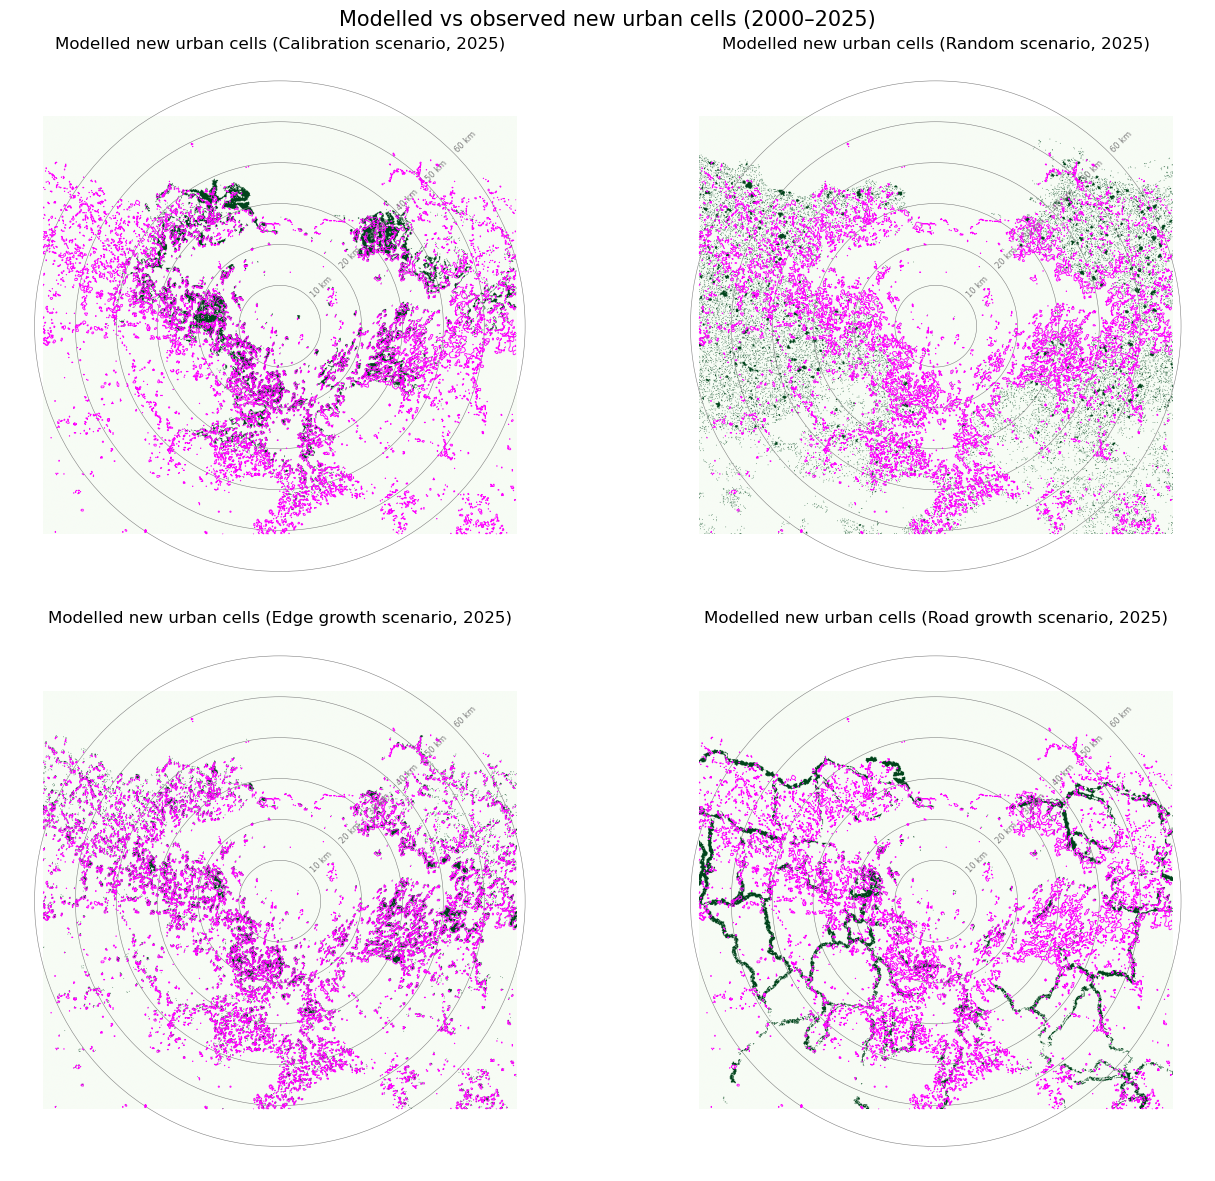

In [ ]:
scenario_name_dict = scenario_name_dict 

new_late_urban_cells_raster = (urban_late_raster == 1) & (urban_early_raster == 0)

fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharex=True, sharey=True)
axes = axes.flatten()

transform = urban_late_raster_meta["transform"]
pixel_width = abs(transform.a)
pixel_height = abs(transform.e)

height, width = urban_late_urban_cells_raster.shape if False else urban_late_raster.shape
center_x, center_y = width / 2, height / 2

for ax, scenario in zip(axes, scenario_list):
    modelled_new = (
        (results_dict[scenario]["025"] > 0) &
        (results_dict[scenario]["025"] < 5)
    )

    ax.imshow(modelled_new, cmap="Greens", vmin=0, vmax=1)

    # Outline observed new-urban cells for comparison
    ax.contour(
        new_late_urban_cells_raster.astype(int),
        levels=[0.5],
        colors="magenta",
        linewidths=0.6,
    )

    for distance_km in [10, 20, 30, 40, 50, 60]:
        radius_x = distance_km * 1000 / pixel_width
        radius_y = distance_km * 1000 / pixel_height

        ring = plt.matplotlib.patches.Ellipse(
            (center_x, center_y),
            width=2 * radius_x,
            height=2 * radius_y,
            fill=False,
            edgecolor="grey",
            linewidth=0.4,
        )
        ax.add_patch(ring)
        ax.text(
            center_x + radius_x / np.sqrt(2),
            center_y - radius_y / np.sqrt(2),
            f"{distance_km} km",
            color="grey",
            fontsize=6,
            rotation=45,
        )

    ax.set_title(f"Modelled new urban cells ({scenario_name_dict.get(scenario, scenario)}, {calibration_years[1]})")
    ax.axis("off")

fig.suptitle(
    f"Modelled vs observed new urban cells ({calibration_years[0]}–{calibration_years[1]})",
    fontsize=15,
)
fig.tight_layout()
plt.show()

## .3 load and compare model results with new allocation functions

In [17]:
# this import loads the calibration scenario (S0a) 
# and three baseline scenarios for comparison: random (S0b), 
# edge-growth (S0c), and road-based growth (S0d)
scenario_list = ['S0a_major roads',  
                 'S0b_all roads', 
                 'S0d_random w 3', 
                 'S0d_random w 6',
                 'S0e_random w 9'] #, 'S0b', 'S0c', 'S0d']
scenario_path_dict = {scenario_list[0]: 'R108/', 
                      scenario_list[1]: 'R109/', 
                      scenario_list[2]: 'R110/', 
                      scenario_list[3]: 'R111/',
                      scenario_list[4]: 'R112/'} # consider the output_folder

baseline_list = ['S_random', 'S_edge', 'S_roadbound']
baseline_path_dict = {
    'S_random': 'R113/',
    'S_edge': 'R114/',
    'S_roadbound': 'R115/'
}

results_dict = load_ascii_files(
    scenarios = scenario_list,
    scenario_path = scenario_path_dict,
    results_folder=ti_city_out_path,
    file_name_template='expansion_income_t',
    export_tiff=False,
    export_path=model_outputs_path,
    silent=False)
baseline_dict = load_ascii_files(
    scenarios = baseline_list,
    scenario_path = baseline_path_dict,
    results_folder=ti_city_out_path,
    file_name_template='expansion_income_t',
    export_tiff=False,
    export_path=model_outputs_path,
    silent=False)
#baseline_dict['Observed'] = {'025':new_cells_observed}
results_table = compile_scenarios_table(
    results_dict = results_dict,
    baseline_dict = baseline_dict,
    exposure_raster = exposure_raster,
    start_year = calibration_years[0],
    cell_area=0.150*0.150, 
    export_results_table=True, 
    export_path=model_outputs_path)
hh_at_input = 28866
print(f"*** Unallocated cells: {hh_at_input - results_table.loc[results_table['Scenario'] == scenario_list[4], 'New urban cells'].values[0]}")

Processing content from: S0a_major roads at ..\model\JAK\data\out\R108
Loading only the final tick for scenario: S0a_major roads
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: S0b_all roads at ..\model\JAK\data\out\R109
Loading only the final tick for scenario: S0b_all roads
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: S0d_random w 3 at ..\model\JAK\data\out\R110
Loading only the final tick for scenario: S0d_random w 3
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: S0d_random w 6 at ..\model\JAK\data\out\R111
Loading only the final tick for scenario: S0d_random w 6
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: S0e_random w 9 at ..\model\JAK\data\out\R112
Loading only the final tick for scenario: S0e_random w 9
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: S_random at ..\model\JAK\data\out\R113
Loading only the fina

# 4. Calibration procedures

## 4.1 Figure of merit (FoM)

In [18]:
from ti_city_08_fuzzy_fom_validation_module import *

# observed new-urban cells: 0/1 int array (urban_late & ~urban_early)
new_cells_observed = observed_new_from_rasters(
    urban_late = urban_late_raster,
    urban_early = urban_early_raster)

# ---- model scenarios ----
fom_table = evaluate_scenario_fom(
    results_dict = results_dict,
    obs_new = new_cells_observed,
    initial_urban = urban_early_raster > 0,
    start_year = calibration_years[0],
    per_tick = 'final',
    variant = 'hits_only',
    case_city = case_city,
    cell_km = 0.150,
    silent = False)

# ---- baselines (same rules, same obs, same grid) ----
baseline_fom_table = evaluate_scenario_fom(
    results_dict = baseline_dict,
    obs_new = new_cells_observed,
    initial_urban = urban_early_raster > 0,
    start_year = calibration_years[0],
    per_tick = 'final',
    variant = 'hits_only',
    case_city = case_city,
    cell_km = 0.150,
    silent = False)
# ---- normalise model rows against the strongest baseline per metric ----
fom_table = normalize_against_baselines(
    fom_table = fom_table,
    baseline_fom_table = baseline_fom_table)

# ---- join onto the (freshly re-initialised) results table ----
results_table = append_validation_to_results_table(
    results_table = results_table,
    fom_table = fom_table,
    export_results_table = False)

Evaluating against 29,559 observed new-urban cells (excl. JAK initial urban & invalid cells).
  S0a_major roads t025: N_sim=28,860 FoM=0.304 fFoM_t1=0.403 fFoM_t2=0.450 fFoM_t3=0.480 fFoM_t5=0.516
  S0b_all roads t025: N_sim=25,720 FoM=0.241 fFoM_t1=0.404 fFoM_t2=0.456 fFoM_t3=0.488 fFoM_t5=0.526
  S0d_random w 3 t025: N_sim=25,703 FoM=0.243 fFoM_t1=0.407 fFoM_t2=0.459 fFoM_t3=0.490 fFoM_t5=0.526
  S0d_random w 6 t025: N_sim=25,732 FoM=0.241 fFoM_t1=0.407 fFoM_t2=0.459 fFoM_t3=0.490 fFoM_t5=0.525
  S0e_random w 9 t025: N_sim=25,713 FoM=0.241 fFoM_t1=0.409 fFoM_t2=0.461 fFoM_t3=0.491 fFoM_t5=0.527
Evaluating against 29,559 observed new-urban cells (excl. JAK initial urban & invalid cells).
  S_random t025: N_sim=28,258 FoM=0.049 fFoM_t1=0.268 fFoM_t2=0.426 fFoM_t3=0.486 fFoM_t5=0.519
  S_edge t025: N_sim=24,556 FoM=0.242 fFoM_t1=0.522 fFoM_t2=0.595 fFoM_t3=0.628 fFoM_t5=0.655
  S_roadbound t025: N_sim=27,590 FoM=0.109 fFoM_t1=0.388 fFoM_t2=0.496 fFoM_t3=0.534 fFoM_t5=0.558


In [16]:
# export the results table to Excel
suffix = f"{scenario_path_dict[scenario_list[0]].rstrip('/')}_{scenario_path_dict[scenario_list[-1]].rstrip('/')}_{calibration_years[0]}_{calibration_years[1]}"
output_file = model_outputs_path / (f"{case_city}_validation_results_{suffix}.xlsx")
results_table.to_excel(output_file, index=False)
print(f"Validation results table exported to {output_file}")

Validation results table exported to C:\Sciebo\05_GIS\JAK\model_outputs\JAK_validation_results_R094_R094_2000_2025.xlsx


In [11]:
from ti_city_08_fuzzy_fom_validation_module import *

# 1. Observed new-urban cells (2000-2025) on the 150 m AOI grid
new_cells_observed = observed_new_from_rasters(urban_late_raster, urban_early_raster) 

fom_table = evaluate_scenario_fom(
    results_dict = results_dict, 
    obs_new = new_cells_observed,
    initial_urban = urban_early_raster > 0,
    start_year=calibration_years[0],
    per_tick = 'final',
    variant = 'hits_only',
    case_city = case_city,
    cell_km = 0.150,
    silent = False
    )

# 3. Normalise against the baselines
fom_table = normalize_against_baselines(fom_table,
    baseline_scenarios=['S_random', 'S_roadbound', 'S_edge'])  # your scenario names

# 4. Join the FoM columns onto your existing results table
results_table = append_validation_to_results_table(results_table, fom_table,
                                                    export_path=model_outputs_path)

Evaluating against 29,559 observed new-urban cells (excl. JAK initial urban & invalid cells).
  S0a t025: N_sim=28,889 FoM=0.275 fFoM_t1=0.373 fFoM_t2=0.422 fFoM_t3=0.454 fFoM_t5=0.490
  S0b t025: N_sim=28,910 FoM=0.051 fFoM_t1=0.256 fFoM_t2=0.413 fFoM_t3=0.478 fFoM_t5=0.510
  S0c t025: N_sim=28,901 FoM=0.561 fFoM_t1=0.721 fFoM_t2=0.753 fFoM_t3=0.768 fFoM_t5=0.776
  S0d t025: N_sim=28,901 FoM=0.135 fFoM_t1=0.194 fFoM_t2=0.237 fFoM_t3=0.274 fFoM_t5=0.342


ValueError: None of the baseline scenarios found in fom_table: ['S_random', 'S_roadbound', 'S_edge']

In [ ]:
# from fuzzy_fom_validation import *
from notebooks.ti_city_08_fuzzy_fom_validation_module import *

# 1. Observed new-urban cells (2000-2025) on the 150 m AOI grid
obs_new = urban_late_raster

# 2. Score every tick of the calibration run
fom_table = evaluate_scenario_fom(
    results_dict = results_dict, 
    obs_new = obs_new,
    initial_urban = urban_early_raster,
    start_year = calibration_years[0],  # 2000 for JAK
    per_tick = 'final',
    variant = 'hits_only',
    case_city = case_city,
    cell_km = 0.150,
    silent = False
    )              # reproduces the earlier 45.2% soft-FoM
                                      # use variant='full' going forward (symmetric)


#null_row = null_fom_baseline(obs_new, eligible_mask=~urban_early_raster, n_seeds=5)

# 4. Join the FoM columns onto your existing results table
results_table = append_validation_to_results_table(results_table, fom_table,
                                                    export_path=model_outputs_path)

## 4.2 Wasserstein distance 
(earth mover's distance, EMD)

## 4.3 L1 distance

## 4.4 Patch metrics

## 4.5 Scalar objective (summary)

# 10. Assess exposure metrics

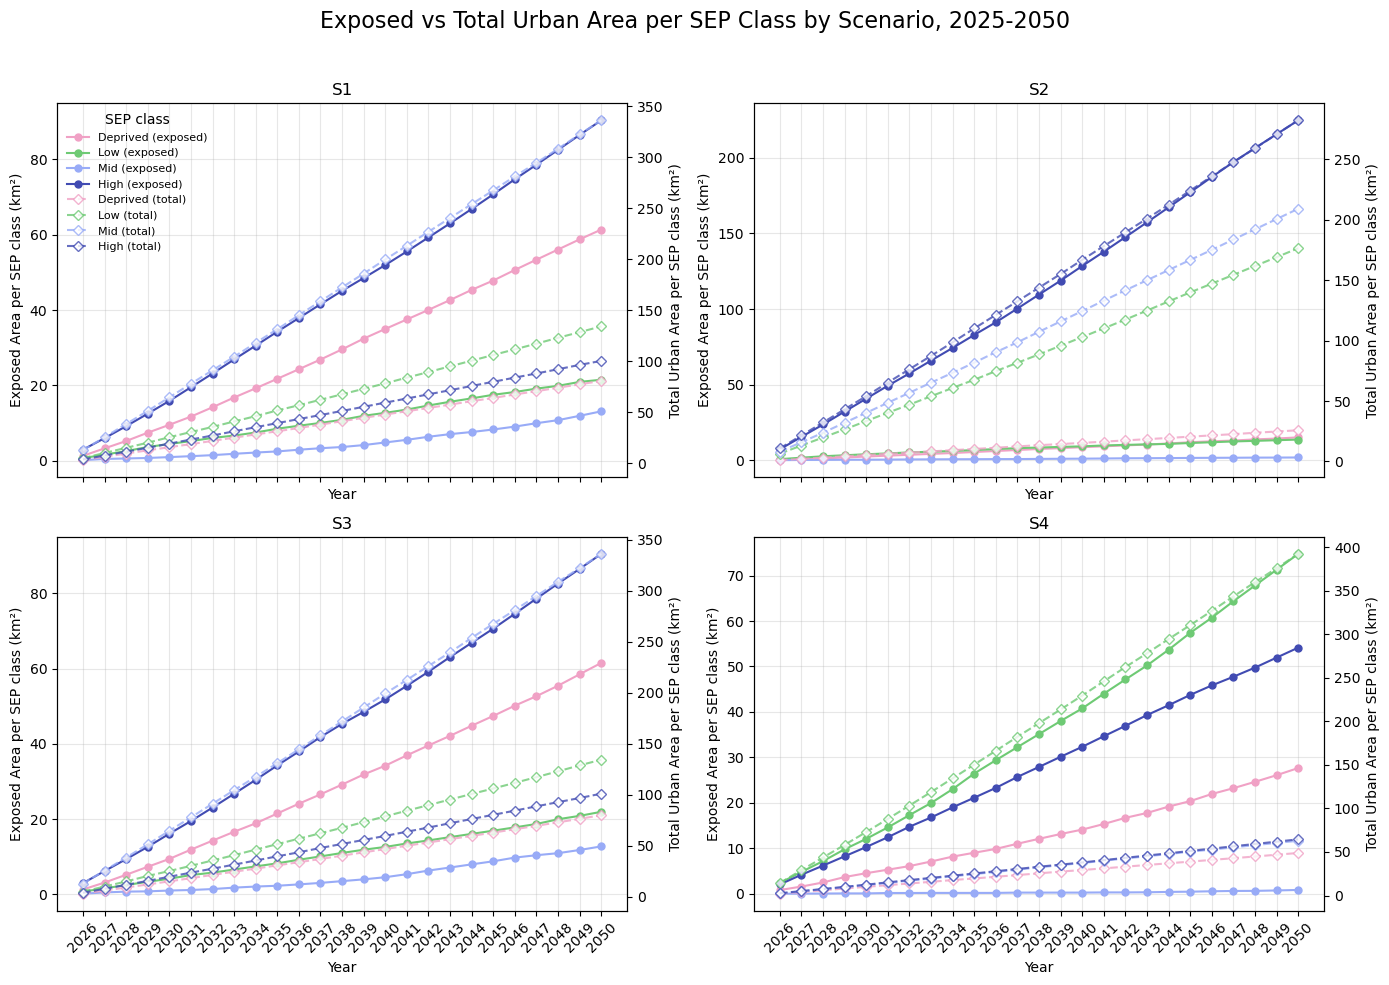

In [ ]:
# using results_table as input, let's plot the results for each scenario. The years should be the x-axis. 
# The exposed area per SEP class will be the y-axis variable
# colours will come from agent_color_dict
# for the labels, we'll use the keys in agent_class_dict
# Create a secondary y-axis for total urban area (non-exposed)
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
axes = axes.flatten()
marker_list = ['o','D']

agent_color_dict = {'low': '#6eca74', 'mid': '#98ABF7', 'high': '#414bb2', 'deprived': '#f0a1c5', 'urban_2022': '#dbdbce'}
for ax, scenario in zip(axes, scenario_list):
        df = results_table[results_table['Scenario'] == scenario].sort_values('Year')
        years = df['Year'].astype(int)
        exposed_mapping = {
                'deprived': 'Urban Area Exposed (deprived)',
                'low': 'Urban Area Exposed (low)',
                'mid': 'Urban Area Exposed (mid)',
                'high': 'Urban Area Exposed (high)'
        }
        
        # Primary axis: exposed areas
        for sep in ['deprived', 'low', 'mid', 'high']:
                col = exposed_mapping[sep]
                #print(col)
                ax.plot(years, df[col], marker=marker_list[0], linestyle='-', markersize=5,  label=f'{sep.capitalize()} (exposed)', color=agent_color_dict[sep])
                
        ax.set_title(scenario.upper())
        ax.set_xlabel('Year')
        ax.tick_params(axis='x', labelcolor='black', rotation=45)
        ax.set_ylabel('Exposed Area per SEP class (km²)', color='black')
        ax.tick_params(axis='y', labelcolor='black', rotation=0)
        ax.grid(alpha=0.3)
        ax.set_xticks(years)
        ax.set_xticklabels(years.astype(str))
        
        # Secondary y-axis: total urban area (non-exposed)
        ax2 = ax.twinx()
        total_mapping = {
                'deprived': 'Urban Area (deprived)',
                'low': 'Urban Area (low)',
                'mid': 'Urban Area (mid)',
                'high': 'Urban Area (high)'
        }
        
        for sep in ['deprived', 'low', 'mid', 'high']:
                col = total_mapping[sep]
                #ax2.plot(years, df[col], marker=marker_list[1], linestyle='--', markersize=6, label=f'{sep.capitalize()} (total)', color=agent_color_dict[sep], alpha=0.8, markerfacecolor='none', markeredgecolor=agent_color_dict[sep], markeredgewidth=1.0)
                filled_marker_style = dict(marker=marker_list[1],  markersize=5,
                           color=agent_color_dict[sep],
                           markerfacecolor='white',
                           alpha=0.8,
                           #markerfacecoloralt='lightsteelblue',
                           linestyle='--',
                           markeredgecolor=agent_color_dict[sep])
                ax2.plot(years, df[col],  label=f'{sep.capitalize()} (total)', **filled_marker_style)
        
        ax2.set_ylabel('Total Urban Area per SEP class (km²)', color='black')
        ax2.tick_params(axis='y', labelcolor='black', rotation=0)
        
        if scenario == scenario_list[0]:
                lines1, labels1 = ax.get_legend_handles_labels()
                lines2, labels2 = ax2.get_legend_handles_labels()
                ax.legend(lines1 + lines2, labels1 + labels2, title='SEP class', 
                                 loc='upper left', frameon=False, fontsize=8)

for ax in axes[len(scenario_list):]:
        ax.set_visible(False)

fig.suptitle(f'Exposed vs Total Urban Area per SEP Class by Scenario, {simulation_years[0]}-{simulation_years[-1]}', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [34]:
# Save the figure as a PNG file with 300 dpi
file_name = f'{case_city}_urban_exposed_areas_line_{S1_path.rstrip("/")}-{S4_path.rstrip("/")}.png'
fig.savefig(model_outputs_path / file_name, dpi=300, format="png", bbox_inches="tight")


0 S1
48.48
1 S2
87.91
2 S3
48.46
3 S4
34.4


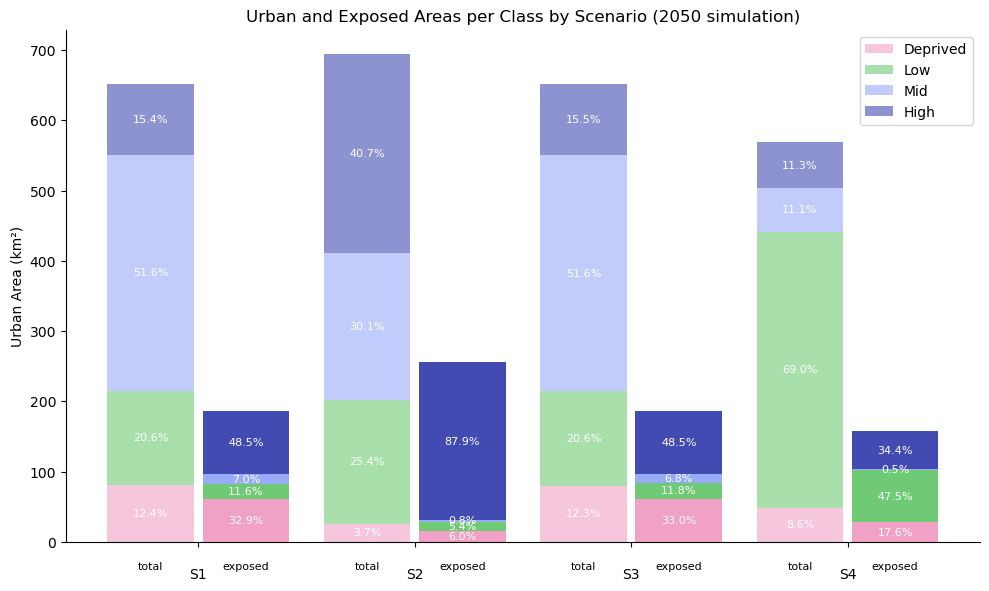

In [31]:
# Create the stacked bar chart
fig, ax = plt.subplots(figsize=(10, 6))
bar_width = 0.4

# Get the last year for each scenario
results_table_last_year = results_table.sort_values("Year").groupby("Scenario").tail(1).reset_index(drop=True)

# Order scenarios: std, ssp1, ssp2, ssp3
scenario_order = ['S1', 'S2', 'S3', 'S4']
results_table_last_year['Scenario'] = pd.Categorical(
    results_table_last_year['Scenario'],
    categories=scenario_order,
    ordered=True,
)
results_table_last_year = results_table_last_year.sort_values('Scenario').reset_index(drop=True)

# Extract data for the stacked bar chart
scenarios = results_table_last_year["Scenario"].tolist()
urban_area_deprived = pd.to_numeric(results_table_last_year["Urban Area (deprived)"], errors='coerce').fillna(0.0).values.astype(float)
urban_area_low = pd.to_numeric(results_table_last_year["Urban Area (low)"], errors='coerce').fillna(0.0).values.astype(float)
urban_area_mid = pd.to_numeric(results_table_last_year["Urban Area (mid)"], errors='coerce').fillna(0.0).values.astype(float)
urban_area_high = pd.to_numeric(results_table_last_year["Urban Area (high)"], errors='coerce').fillna(0.0).values.astype(float)

# Extract data for the exposed areas
urban_exposed_deprived = pd.to_numeric(results_table_last_year["Urban Area Exposed (deprived)"], errors='coerce').fillna(0.0).values.astype(float)
urban_exposed_low = pd.to_numeric(results_table_last_year["Urban Area Exposed (low)"], errors='coerce').fillna(0.0).values.astype(float)
urban_exposed_mid = pd.to_numeric(results_table_last_year["Urban Area Exposed (mid)"], errors='coerce').fillna(0.0).values.astype(float)
urban_exposed_high = pd.to_numeric(results_table_last_year["Urban Area Exposed (high)"], errors='coerce').fillna(0.0).values.astype(float)

# Normalize the data to percentages
urban_area_deprived_percentage = pd.to_numeric(results_table_last_year['Urban Area (deprived) Percentage'], errors='coerce').fillna(0.0).values.astype(float)
urban_area_low_percentage = pd.to_numeric(results_table_last_year['Urban Area (low) Percentage'], errors='coerce').fillna(0.0).values.astype(float)
urban_area_mid_percentage = pd.to_numeric(results_table_last_year['Urban Area (mid) Percentage'], errors='coerce').fillna(0.0).values.astype(float)
urban_area_high_percentage = pd.to_numeric(results_table_last_year['Urban Area (high) Percentage'], errors='coerce').fillna(0.0).values.astype(float)

urban_exposed_deprived_percentage = pd.to_numeric(results_table_last_year['Urban Area Exposed (deprived) Percentage'], errors='coerce').fillna(0.0).values.astype(float)
urban_exposed_low_percentage = pd.to_numeric(results_table_last_year['Urban Area Exposed (low) Percentage'], errors='coerce').fillna(0.0).values.astype(float)
urban_exposed_mid_percentage = pd.to_numeric(results_table_last_year['Urban Area Exposed (mid) Percentage'], errors='coerce').fillna(0.0).values.astype(float)
urban_exposed_high_percentage = pd.to_numeric(results_table_last_year['Urban Area Exposed (high) Percentage'], errors='coerce').fillna(0.0).values.astype(float)

# Adjust the x positions for the second set of bars
x_positions = np.arange(len(scenarios))
x_positions_exposed = x_positions + bar_width * 1.1

# Plot each class as a stack
p1 = ax.bar(scenarios, urban_area_deprived, bar_width, label="Deprived")
p2 = ax.bar(scenarios, urban_area_low, bar_width, bottom=urban_area_deprived, label="Low")
p3 = ax.bar(scenarios, urban_area_mid, bar_width, bottom=urban_area_deprived + urban_area_low, label="Mid")
p4 = ax.bar(scenarios, urban_area_high, bar_width, bottom=urban_area_deprived + urban_area_low + urban_area_mid, label="High")

# Use the colors from agent_color_dict
colors = [agent_color_dict['deprived'], agent_color_dict['low'], agent_color_dict['mid'], agent_color_dict['high']]

# Apply colors to all bars in each stack with reduced alpha
alpha_decay = 0.6
for bar, color in zip(p1, [colors[0]] * len(p1)):
    bar.set_facecolor(color)
    bar.set_alpha(alpha_decay)
for bar, color in zip(p2, [colors[1]] * len(p2)):
    bar.set_facecolor(color)
    bar.set_alpha(alpha_decay)
for bar, color in zip(p3, [colors[2]] * len(p3)):
    bar.set_facecolor(color)
    bar.set_alpha(alpha_decay)
for bar, color in zip(p4, [colors[3]] * len(p4)):
    bar.set_facecolor(color)
    bar.set_alpha(alpha_decay)

# Plot the exposed areas as a second series of bars
p5 = ax.bar(x_positions_exposed, urban_exposed_deprived, bar_width) #, label="Exposed (Deprived)"
p6 = ax.bar(x_positions_exposed, urban_exposed_low, bar_width, bottom=urban_exposed_deprived)#, label="Exposed (Low)")
p7 = ax.bar(x_positions_exposed, urban_exposed_mid, bar_width, bottom=urban_exposed_deprived + urban_exposed_low) #, label="Exposed (Mid)")
p8 = ax.bar(x_positions_exposed, urban_exposed_high, bar_width, bottom=urban_exposed_deprived + urban_exposed_low + urban_exposed_mid)#, label="Exposed (High)")

# Apply colors to the exposed bars
for bar, color in zip(p5, [colors[0]] * len(p5)):
    bar.set_facecolor(color)
for bar, color in zip(p6, [colors[1]] * len(p6)):
    bar.set_facecolor(color)
for bar, color in zip(p7, [colors[2]] * len(p7)):
    bar.set_facecolor(color)
for bar, color in zip(p8, [colors[3]] * len(p8)):
    bar.set_facecolor(color)

# Add 'total' label under the total urban area bars
for xpos, label in zip(x_positions, scenarios):
    ax.text(xpos, -35, 'total', ha='center', va='center', fontsize=8, color='black')

# Add 'exposed' label under the exposed area bars
for xpos, label in zip(x_positions_exposed, scenarios):
    ax.text(xpos, -35, 'exposed', ha='center', va='center', fontsize=8, color='black')

# Add percentages for each class inside the corresponding area of the graph
for i, scenario in enumerate(scenarios):
    # Total urban area percentages
    print(i, scenario)
    ax.text(x_positions[i], urban_area_deprived[i] / 2, f"{urban_area_deprived_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions[i], urban_area_deprived[i] + urban_area_low[i] / 2, f"{urban_area_low_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions[i], urban_area_deprived[i] + urban_area_low[i] + urban_area_mid[i] / 2, f"{urban_area_mid_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions[i], urban_area_deprived[i] + urban_area_low[i] + urban_area_mid[i] + urban_area_high[i] / 2, f"{urban_area_high_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')

    # Exposed urban area percentages
    print(urban_exposed_high_percentage[i])
    ax.text(x_positions_exposed[i], urban_exposed_deprived[i] / 2, f"{urban_exposed_deprived_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions_exposed[i], urban_exposed_deprived[i] + urban_exposed_low[i] / 2, f"{urban_exposed_low_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions_exposed[i], urban_exposed_deprived[i] + urban_exposed_low[i] + urban_exposed_mid[i] / 2, f"{urban_exposed_mid_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions_exposed[i], urban_exposed_deprived[i] + urban_exposed_low[i] + urban_exposed_mid[i] + urban_exposed_high[i] / 2, f"{urban_exposed_high_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')

# Adjust x-axis ticks and labels
ax.set_xticks(x_positions + bar_width * 1.1 / 2)
ax.set_xticklabels(
    [label.upper() if isinstance(label, str) else '' for label in scenarios],
    y=-0.03,
)
# Add labels, title, and legend
#ax.set_xlabel("Scenario", fontsize=12)
ax.set_ylabel("Urban Area (km²)")
ax.set_title("Urban and Exposed Areas per Class by Scenario (2050 simulation)")
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Show the plot
plt.tight_layout()
plt.show()

In [32]:
# Save the figure as a PNG file with 300 dpi
file_name = f'{case_city}_urban_exposed_areas_bar_{S1_path.rstrip("/")}-{S4_path.rstrip("/")}.png'
fig.savefig(model_outputs_path / file_name, dpi=300, format="png", bbox_inches="tight")


In [35]:
# Normalize the data to percentages for stacked bars
urban_area_deprived_percentage = (urban_area_deprived / urban_area_total) * 100
urban_area_low_percentage = (urban_area_low / urban_area_total) * 100
urban_area_mid_percentage = (urban_area_mid / urban_area_total) * 100
urban_area_high_percentage = (urban_area_high / urban_area_total) * 100

urban_exposed_deprived_percentage = (urban_exposed_deprived / urban_exposed_total) * 100
urban_exposed_low_percentage = (urban_exposed_low / urban_exposed_total) * 100
urban_exposed_mid_percentage = (urban_exposed_mid / urban_exposed_total) * 100
urban_exposed_high_percentage = (urban_exposed_high / urban_exposed_total) * 100

# Plot each class as a stack normalized to 100%
p1 = ax.bar(scenarios, urban_area_deprived_percentage, bar_width, label="Deprived")
p2 = ax.bar(scenarios, urban_area_low_percentage, bar_width, bottom=urban_area_deprived_percentage, label="Low")
p3 = ax.bar(scenarios, urban_area_mid_percentage, bar_width, bottom=urban_area_deprived_percentage + urban_area_low_percentage, label="Mid")
p4 = ax.bar(scenarios, urban_area_high_percentage, bar_width, bottom=urban_area_deprived_percentage + urban_area_low_percentage + urban_area_mid_percentage, label="High")

# Plot the exposed areas as a second series of bars normalized to 100%
p5 = ax.bar(x_positions_exposed, urban_exposed_deprived_percentage, bar_width)
p6 = ax.bar(x_positions_exposed, urban_exposed_low_percentage, bar_width, bottom=urban_exposed_deprived_percentage)
p7 = ax.bar(x_positions_exposed, urban_exposed_mid_percentage, bar_width, bottom=urban_exposed_deprived_percentage + urban_exposed_low_percentage)
p8 = ax.bar(x_positions_exposed, urban_exposed_high_percentage, bar_width, bottom=urban_exposed_deprived_percentage + urban_exposed_low_percentage + urban_exposed_mid_percentage)

# Adjust y-axis label to reflect percentages
ax.set_ylabel("Percentage (%)")
p2 = ax.bar(scenarios, urban_area_low, bar_width, bottom=urban_area_deprived, label="Low")
p3 = ax.bar(scenarios, urban_area_mid, bar_width, bottom=urban_area_deprived + urban_area_low, label="Mid")
p4 = ax.bar(scenarios, urban_area_high, bar_width, bottom=urban_area_deprived + urban_area_low + urban_area_mid, label="High")

# Use the colors from agent_color_dict
colors = [agent_color_dict['deprived'], agent_color_dict['low'], agent_color_dict['mid'], agent_color_dict['high']]

# Apply colors to all bars in each stack
for bar, color in zip(p1, [colors[0]] * len(p1)):
    bar.set_facecolor(color)
for bar, color in zip(p2, [colors[1]] * len(p2)):
    bar.set_facecolor(color)
for bar, color in zip(p3, [colors[2]] * len(p3)):
    bar.set_facecolor(color)
for bar, color in zip(p4, [colors[3]] * len(p4)):
    bar.set_facecolor(color)

# Plot the exposed areas as a second series of bars
p5 = ax.bar(x_positions_exposed, urban_exposed_deprived, bar_width) #, label="Exposed (Deprived)"
p6 = ax.bar(x_positions_exposed, urban_exposed_low, bar_width, bottom=urban_exposed_deprived)#, label="Exposed (Low)")
p7 = ax.bar(x_positions_exposed, urban_exposed_mid, bar_width, bottom=urban_exposed_deprived + urban_exposed_low) #, label="Exposed (Mid)")
p8 = ax.bar(x_positions_exposed, urban_exposed_high, bar_width, bottom=urban_exposed_deprived + urban_exposed_low + urban_exposed_mid)#, label="Exposed (High)")

# Apply colors to the exposed bars
for bar, color in zip(p5, [colors[0]] * len(p5)):
    bar.set_facecolor(color)
for bar, color in zip(p6, [colors[1]] * len(p6)):
    bar.set_facecolor(color)
for bar, color in zip(p7, [colors[2]] * len(p7)):
    bar.set_facecolor(color)
for bar, color in zip(p8, [colors[3]] * len(p8)):
    bar.set_facecolor(color)

# Add 'total' label under the total urban area bars
for xpos, label in zip(x_positions, scenarios):
    ax.text(xpos, -35, 'total', ha='center', va='center', fontsize=8, color='black')

# Add 'exposed' label under the exposed area bars
for xpos, label in zip(x_positions_exposed, scenarios):
    ax.text(xpos, -35, 'exposed', ha='center', va='center', fontsize=8, color='black')

# Add percentages for each class inside the corresponding area of the graph
for i, scenario in enumerate(scenarios):
    # Total urban area percentages
    ax.text(x_positions[i], urban_area_deprived_percentage[i] / 2, f"{urban_area_deprived_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions[i], urban_area_deprived_percentage[i] + urban_area_low_percentage[i] / 2, f"{urban_area_low_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions[i], urban_area_deprived_percentage[i] + urban_area_low_percentage[i] + urban_area_mid_percentage[i] / 2, f"{urban_area_mid_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions[i], urban_area_deprived_percentage[i] + urban_area_low_percentage[i] + urban_area_mid_percentage[i] + urban_area_high_percentage[i] / 2, f"{urban_area_high_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')

    # Exposed urban area percentages
    ax.text(x_positions_exposed[i], urban_exposed_deprived_percentage[i] / 2, f"{urban_exposed_deprived_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions_exposed[i], urban_exposed_deprived_percentage[i] + urban_exposed_low_percentage[i] / 2, f"{urban_exposed_low_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions_exposed[i], urban_exposed_deprived_percentage[i] + urban_exposed_low_percentage[i] + urban_exposed_mid_percentage[i] / 2, f"{urban_exposed_mid_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')
    ax.text(x_positions_exposed[i], urban_exposed_deprived_percentage[i] + urban_exposed_low_percentage[i] + urban_exposed_mid_percentage[i] + urban_exposed_high_percentage[i] / 2, f"{urban_exposed_high_percentage[i]:.1f}%", ha='center', va='center', fontsize=8, color='white')

# Adjust x-axis ticks and labels
ax.set_xticks(x_positions + bar_width * 1.1 / 2)
ax.set_xticklabels([label.upper() for label in scenarios], y=-0.03)
# Add labels, title, and legend
#ax.set_xlabel("Scenario", fontsize=12)
ax.set_ylabel("Urban Area (km²)")
ax.set_title("Urban and Exposed Areas per Class by Scenario (2050 simulation)")
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Show the plot
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

# (optional) Compare results with HDI calibration data

In [54]:
admin3_file = interim_path / (case_city + '_POP_HDI_component_estimates_ADMlvl3_A.gpkg')
admin3_gdf = gpd.read_file(admin3_file)

In [55]:
# calculate the exposed area for each admin 3 unit
admin3_gdf['exp_surface'] = rasterstats.zonal_stats(admin3_gdf, exposure_raster, affine=exposure_raster_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
admin3_gdf['exp_surface'] = admin3_gdf['exp_surface'].apply(lambda x: x['sum'] if isinstance(x, dict) else np.nan)

In [63]:
# calculate population for each socioeconomic profile per admin 3 unit
modelled_pop_list = ['pop_deprived_model', 'pop_low_model', 'pop_mid_model', 'pop_high_model']
model_scenario_list = ['std', 'ssp1', 'ssp2','ssp3']
if case_city == 'JAK':
    cell_conversion_factor = 310.34 #determined by the average number of households per pixel
else:
    cell_conversion_factor = 1 # need to determine this for other cases

#admin3_gdf['exp_surface'] = rasterstats.zonal_stats(admin3_gdf, exposure_raster, affine=array_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
for scenario in model_scenario_list:
    var_deprived = 'pop_deprived_model_' + scenario
    var_low = 'pop_low_model_' + scenario
    var_mid = 'pop_mid_model_' + scenario
    var_high = 'pop_high_model_' + scenario
    deprived_array = np.where(results_dict[scenario] == 4, 1, 0)
    admin3_gdf[var_deprived] = rasterstats.zonal_stats(admin3_gdf, deprived_array, affine=array_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
    admin3_gdf[var_deprived] = admin3_gdf[var_deprived].apply(lambda x: x['sum'] if isinstance(x, dict) else np.nan) * cell_conversion_factor
    low_array = np.where(results_dict[scenario] == 1, 1, 0)
    admin3_gdf[var_low] = rasterstats.zonal_stats(admin3_gdf, low_array, affine=array_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
    admin3_gdf[var_low] = admin3_gdf[var_low].apply(lambda x: x['sum'] if isinstance(x, dict) else np.nan) * cell_conversion_factor
    mid_array = np.where(results_dict[scenario] == 2, 1, 0)
    admin3_gdf[var_mid] = rasterstats.zonal_stats(admin3_gdf, mid_array, affine=array_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
    admin3_gdf[var_mid] = admin3_gdf[var_mid].apply(lambda x: x['sum'] if isinstance(x, dict) else np.nan) * cell_conversion_factor
    high_array = np.where(results_dict[scenario] == 3, 1, 0)
    admin3_gdf[var_high] = rasterstats.zonal_stats(admin3_gdf, high_array, affine=array_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
    admin3_gdf[var_high] = admin3_gdf[var_high].apply(lambda x: x['sum'] if isinstance(x, dict) else np.nan) * cell_conversion_factor

In [64]:
admin3_gdf.loc[:,['pop_deprived_model_std','pop_mid_model_std','pop_deprived_model_ssp1','pop_mid_model_ssp1']].head()

,pop_deprived_model_std,pop_mid_model_std,pop_deprived_model_ssp1,pop_mid_model_ssp1
0,16448.02,10551.56,15517.0,47171.68
1,NaN,310.34,NaN,310.34
2,22965.16,19241.08,13965.3,49964.74
3,NaN,931.02,NaN,1862.04
4,NaN,931.02,NaN,1862.04


In [65]:
# add the 2025 population
for scenario in model_scenario_list:
    var_deprived = 'pop_deprived_model_' + scenario 
    var_low = 'pop_low_model_' + scenario 
    var_mid = 'pop_mid_model_' + scenario 
    var_high = 'pop_high_model_' + scenario
    admin3_gdf[var_deprived] = np.round(admin3_gdf[var_deprived] + admin3_gdf['pop_deprived_2025'], 2)
    admin3_gdf[var_low] = np.round(admin3_gdf[var_low] + admin3_gdf['pop_low_2025'], 2)
    admin3_gdf[var_mid] = np.round(admin3_gdf[var_mid] + admin3_gdf['pop_medium_2015'] ,2)
    admin3_gdf[var_high] = np.round(admin3_gdf[var_high] + admin3_gdf['pop_high_2025'] ,2)

admin3_gdf.loc[:,['pop_deprived_model_std','pop_mid_model_std','pop_deprived_model_ssp1','pop_mid_model_ssp1']].head()


,pop_deprived_model_std,pop_mid_model_std,pop_deprived_model_ssp1,pop_mid_model_ssp1
0,42049.47,10551.56,41118.45,47171.68
1,NaN,61755.09,NaN,61755.09
2,80454.88,19241.08,71455.02,49964.74
3,NaN,26038.88,NaN,26969.90
4,NaN,25478.96,NaN,26409.98


In [68]:
# calculate the proportional exposed population for each admin 3 unit and scenario
for scenario in model_scenario_list:
    var_deprived = 'pop_deprived_model_exp_' + scenario 
    var_low = 'pop_low_model_exp_' + scenario 
    var_mid = 'pop_mid_model_exp_' + scenario 
    var_high = 'pop_high_model_exp_' + scenario

    ref_var_deprived = 'pop_deprived_model_' + scenario 
    ref_var_low = 'pop_low_model_' + scenario 
    ref_var_mid = 'pop_mid_model_' + scenario 
    ref_var_high = 'pop_high_model_' + scenario
    ref_var_total = 'pop_total_model_' + scenario

    admin3_gdf[ref_var_total] = admin3_gdf[ref_var_deprived] + admin3_gdf[ref_var_low] + admin3_gdf[ref_var_mid] + admin3_gdf[ref_var_high] 
    admin3_gdf[var_deprived] = (admin3_gdf[ref_var_deprived]/admin3_gdf[ref_var_total] )* admin3_gdf['exp_surface']
    admin3_gdf[var_low] = (admin3_gdf[ref_var_low]/admin3_gdf[ref_var_total] )* admin3_gdf['exp_surface']
    admin3_gdf[var_mid] = (admin3_gdf[ref_var_mid]/admin3_gdf[ref_var_total] )* admin3_gdf['exp_surface']
    admin3_gdf[var_high] = (admin3_gdf[ref_var_high]/admin3_gdf[ref_var_total] )* admin3_gdf['exp_surface']

# calculate the proportional exposed population for 2015 and 2025

var_deprived_early = f'pop_deprived_exp_{calibration_years[0]}'
var_low_early = f'pop_low_exp_{calibration_years[0]}'
var_mid_early = f'pop_mid_exp_{calibration_years[0]}'
var_high_early = f'pop_high_model_exp_{calibration_years[0]}'

var_deprived_late = f'pop_deprived_exp_{calibration_years[1]}'
var_low_late = f'pop_low_exp_{calibration_years[1]}'
var_mid_late = f'pop_mid_exp_{calibration_years[1]}'
var_high_late = f'pop_high_exp_{calibration_years[1]}'

ref_var_deprived_early = f'pop_deprived_{calibration_years[0]}'
ref_var_low_early = f'pop_low_{calibration_years[0]}'
ref_var_mid_early = f'pop_medium_{calibration_years[0]}'
ref_var_high_early = f'pop_high_{calibration_years[0]}'
ref_var_total_early = f'pop_total_{calibration_years[0]}'

ref_var_deprived_late = f'pop_deprived_{calibration_years[1]}'
ref_var_low_late = f'pop_low_{calibration_years[1]}'
ref_var_mid_late = f'pop_medium_{calibration_years[1]}'
ref_var_high_late = f'pop_high_{calibration_years[1]}'
ref_var_total_late = f'pop_total_{calibration_years[1]}'

admin3_gdf[ref_var_total_early] = admin3_gdf[ref_var_deprived_early] + admin3_gdf[ref_var_low_early] + admin3_gdf[ref_var_mid_early] + admin3_gdf[ref_var_high_early] 

admin3_gdf[var_deprived_early] = (admin3_gdf[ref_var_deprived_early]/admin3_gdf[ref_var_total_early] )* admin3_gdf['exp_surface']
admin3_gdf[var_low_early] = (admin3_gdf[ref_var_low_early]/admin3_gdf[ref_var_total_early] )* admin3_gdf['exp_surface']
admin3_gdf[var_mid_early] = (admin3_gdf[ref_var_mid_early]/admin3_gdf[ref_var_total_early] )* admin3_gdf['exp_surface']
admin3_gdf[var_high_early] = (admin3_gdf[ref_var_high_early]/admin3_gdf[ref_var_total_early] )* admin3_gdf['exp_surface']

admin3_gdf[ref_var_total_late] = admin3_gdf[ref_var_deprived_late] + admin3_gdf[ref_var_low_late] + admin3_gdf[ref_var_mid_late] + admin3_gdf[ref_var_high_late] 

admin3_gdf[var_deprived_late] = (admin3_gdf[ref_var_deprived_late]/admin3_gdf[ref_var_total_late] )* admin3_gdf['exp_surface']
admin3_gdf[var_low_late] = (admin3_gdf[ref_var_low_late]/admin3_gdf[ref_var_total_late] )* admin3_gdf['exp_surface']
admin3_gdf[var_mid_late] = (admin3_gdf[ref_var_mid_late]/admin3_gdf[ref_var_total_late] )* admin3_gdf['exp_surface']
admin3_gdf[var_high_late] = (admin3_gdf[ref_var_high_late]/admin3_gdf[ref_var_total_late] )* admin3_gdf['exp_surface']

In [69]:
# export a shapefile with the statistics
file_name = interim_path / (case_city + f'_POP_model_exposure_estimates_ADMlvl3_A.gpkg')
#admin3_file = interim_path / (case_city + '_POP_HDI_component_estimates_ADMlvl3_A.gpkg')
admin3_gdf.to_file(file_name, driver='GPKG')

In [70]:
# Create a summary table of exposed population for each scenario, including early and late calibration years
exposed_pop_summary = {}

scenarios_to_include = ['2015', '2025'] + model_scenario_list

for scenario in scenarios_to_include:
    if scenario == '2015':
        var_deprived = var_deprived_early
        var_low = var_low_early
        var_mid = var_mid_early
        var_high = var_high_early
    elif scenario == '2025':
        var_deprived = var_deprived_late
        var_low = var_low_late
        var_mid = var_mid_late
        var_high = var_high_late
    else:
        var_deprived = 'pop_deprived_model_exp_' + scenario 
        var_low = 'pop_low_model_exp_' + scenario 
        var_mid = 'pop_mid_model_exp_' + scenario 
        var_high = 'pop_high_model_exp_' + scenario
    
    exposed_pop_summary[scenario] = {
        'Exposed Pop (Deprived)': np.round(admin3_gdf[var_deprived].sum(),2),
        'Exposed Pop (Low)': np.round(admin3_gdf[var_low].sum(), 2),
        'Exposed Pop (Mid)': np.round(admin3_gdf[var_mid].sum(), 2),
        'Exposed Pop (High)': np.round(admin3_gdf[var_high].sum(), 2)
    }

# Convert to DataFrame
exposed_pop_table = pd.DataFrame.from_dict(exposed_pop_summary, orient='index')
exposed_pop_table


,Exposed Pop (Deprived),Exposed Pop (Low),Exposed Pop (Mid),Exposed Pop (High)
2015,58770.97,34744.32,15768.87,6876.84
2025,61855.62,32418.99,15216.07,6670.32
std,8577.57,19241.69,6973.07,6306.66
ssp1,6928.35,12688.25,8930.23,8745.16
ssp2,10282.48,20310.07,7033.75,6366.70
ssp3,7505.59,18918.75,5120.30,3190.36


In [42]:
# calculate the exposure for each socioeconomic profile based on the proportion of exposed area and of that population group in each admin 3 unit
exp_deprived_early = 
exp_low_early
exp_mid_early
exp_high_early

exp_deprived_late = 
exp_low_late
exp_mid_late
exp_high_late

exp_deprived_model = 
exp_low_model
exp_mid_model
exp_high_model

SyntaxError: invalid syntax (3929900972.py, line 2)

# The end (for now).

## NetLogo scripts (for reference/development)
just holding them here for now

In [ ]:
(count households with [(income-status = 1) and (LIH-movement = 0)] ) # LI HH left
(count households with [(income-status = 2) and (MIH-movement = 0)] ) # MI HH left
(count households with [(income-status = 3) and (HIH-movement = 0)] ) # HI HH left
(count households with [(income-status = 4) and (DPH-movement = 0)] ) # deprived HH left

In [ ]:
plot ((count patches with [DP-movement = 1 and new-urban = 1]) / (1 + count patches with [ new-urban = 1])) * 100
plot ((count patches with [DP-movement = 1 and informality = 1]) / (1 + count patches with [DP-movement = 1])) * 100
plot ((count patches with [DP-movement = 1 and informal_avail = 1]) / (1 + count patches with [ new-urban = 1 and informal_avail = 1])) * 100

In [ ]:
plot ((count patches with [LI-movement = 1 and new-urban = 1]) / (1 + count patches with [ new-urban = 1])) * 100
plot (((count patches with [MI-movement = 1 and new-urban = 1]) + (count patches with [pMED-movement = 1 and new-urban = 1])) / (1 + count patches with [ new-urban = 1 ])) * 100
plot (((count patches with [HI-movement = 1 and new-urban = 1]) + (count patches with [pHED-movement = 1 and new-urban = 1])) / (1 + count patches with [ new-urban = 1 ])) * 100

In [ ]:
plot (((count patches with [HI-movement = 1 and informality = 1]) + (count patches with [pHED-movement = 1 and informality = 1])) / ((1 + count patches with [HI-movement = 1]) + (count patches with [pHED-movement = 1]))) * 100
plot (((count patches with [MI-movement = 1 and informality = 1]) + (count patches with [pMED-movement = 1 and informality = 1])) / ((1 + count patches with [MI-movement = 1]) + (count patches with [pMED-movement = 1]))) * 100

In [ ]:
(ifelse 
    scenario = "standard" 
    [ 
      ] ;; standard true
    [ ifelse scenario = "SSP1" ;; else
      [ 
        ] ;; SSP1 true (standard false)
      [ ifelse scenario = "SSP2" ;; else
        [ 
          ] ;; SSP2 true 
        [ if scenario = "SSP3" ;; else
          [  
            ] ;; SSP3 true 
        ] ;; SSP3 false
      ] ;; SSP2 false
    ] ;; SSP1 false
  )

In [ ]:
(ifelse 
    scenario = "standard" 
    [ set 
     [ household-number percent-deprived-households percent-low-income-households percent-mid-income-households percent-high-income-households slope_coefficient critical_slope development_control] 
     [ 23959 10 30 50 10 80 17 50 ]
      ] ;; standard true
    [ ifelse scenario = "SSP1" ;; standard else
      [ set 
       [ household-number percent-deprived-households percent-low-income-households percent-mid-income-households percent-high-income-households slope_coefficient critical_slope development_control] 
       [ 31677 7 21 55 17 80 17 80 ] 
        ] ;; SSP1 true (standard false)
      [ ifelse scenario = "SSP2" ;; SSP1 else
       [ set
        [ household-number percent-deprived-households percent-low-income-households percent-mid-income-households percent-high-income-households slope_coefficient critical_slope development_control] 
        [ 51168 10 30 50 10 80 25 50 ] 
        ]  ;; SSP2 true 
        [ if scenario = "SSP3" ;; SSP2 else
         [ set 
          [ household-number percent-deprived-households percent-low-income-households percent-mid-income-households percent-high-income-households slope_coefficient critical_slope development_control] 
          [ 71629 17 48 28 7 80 35 30 ] 
        ] ;; SSP3 true 
        ] ;; closing SSP3
      ] ;; closing SSP2 
    ] ;; closing SSP1 
)

In [ ]:
Allocation error
Requested 3,438 random agents from a set of only 3,183 agents.
error while observer running MAX-N-OF
  called by procedure MAKE-LOW-INCOME-HOUSEHOLD-DEVELOPMENT
  called by procedure GO
  called by Button 'Go'